# CareerPath AI – Model Training and Evaluation

## Objective
Train machine learning classification models to predict suitable career pathway labels from student education, specialization, academic scores, certifications, and skill profiles.

## Tasks
1. Load the prepared career dataset.
2. Separate input features and target.
3. Split data into training and testing sets.
4. Build preprocessing and classification pipelines.
5. Train baseline and candidate models.
6. Evaluate model performance.
7. Compare models and interpret results.
8. Save the selected model.

**Target variable:** `Recommended Career`

**Dataset:** 9,000 student profiles

**Classification classes:** 30 career categories


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import joblib

print("Model training libraries imported successfully!")

Model training libraries imported successfully!


In [2]:
# Define dataset path
DATA_PATH = Path("../data/processed/career_dataset_normalized.csv")

# Load dataset
career_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", career_df.shape)

display(career_df.head())

Dataset loaded successfully!
Dataset shape: (9000, 16)


,Education Level,Specialization,Skills,Certifications,CGPA/Percentage,Recommended Career,Certification_Status,Score_Type,Score_Value,Technical_Skills_Parsed,Soft_Skills_Parsed,Skills_Gained_Parsed,Technical_Skill_Count,Soft_Skill_Count,Skills_Gained_Count,Recommended_Career_Original
0,BA,Agriculture,Technical: Microsoft Excel; Python; Data analy...,Not specified,8.22,M.Sc Biotechnology / Microbiology / Life Sciences,Not specified,CGPA,8.22,Microsoft Excel; Python; Data analysis; Biolog...,Critical thinking; Problem-solving,Research methods; Data analysis; Biology funda...,4,2,5,M.Sc Biotechnology / Microbiology / Life Sciences
1,Class 10,Not yet selected,Technical: Digital creativity; Visual storytel...,Introductory online course,56.00,Arts / Humanities or a relevant design-oriente...,Provided,Percentage,56.00,Digital creativity; Visual storytelling,Research; Communication,Design fundamentals; Drawing,2,2,2,Arts / Humanities or a relevant design-oriente...
2,Class 10,Not yet selected,Technical: Subject knowledge; Presentation | S...,Introductory online course,84.50,Choose a suitable stream based on preferred te...,Provided,Percentage,84.50,Subject knowledge; Presentation,Patience; Empathy; Adaptability,Subject knowledge; Communication,2,3,2,Choose a suitable stream based on preferred te...
3,Class 12,CEC,Technical: Planning; Excel basics | Soft: Rese...,Basic computer course,40.80,B.Com / BBA / B.A. Economics,Provided,Percentage,40.80,Planning; Excel basics,Research; Teamwork; Presentation; Leadership,Planning; Presentation; Business communication,2,4,3,B.Com / BBA / B.A. Economics
4,B.Des,Pharmacy,Technical: Environmental awareness; Python; Ob...,SWAYAM certificate,7.27,M.Sc Agriculture / Horticulture / Food Science...,Provided,CGPA,7.27,Environmental awareness; Python; Observation; ...,Research; Presentation; Adaptability; Leadership,Data recording; Data analysis; Environmental a...,5,4,4,M.Sc Agriculture / Horticulture / Food Science...


In [3]:
# Define input features
feature_columns = [
    "Education Level",
    "Specialization",
    "Certifications",
    "Score_Type",
    "Score_Value",
    "Technical_Skills_Parsed",
    "Soft_Skills_Parsed",
    "Skills_Gained_Parsed"
]

# Separate features and target
X = career_df[feature_columns]
y = career_df["Recommended Career"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:", y.name)
print("Number of career classes:", y.nunique())

print("\nMissing values in input features:", X.isnull().sum().sum())
print("Missing values in target:", y.isnull().sum())

Input features shape: (9000, 8)
Target shape: (9000,)

Input features:
['Education Level', 'Specialization', 'Certifications', 'Score_Type', 'Score_Value', 'Technical_Skills_Parsed', 'Soft_Skills_Parsed', 'Skills_Gained_Parsed']

Target variable: Recommended Career
Number of career classes: 30

Missing values in input features: 0
Missing values in target: 0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining career classes:", y_train.nunique())
print("Testing career classes:", y_test.nunique())

Training data: (7200, 8)
Testing data: (1800, 8)

Training target: (7200,)
Testing target: (1800,)

Training career classes: 30
Testing career classes: 30


In [5]:
# Define feature groups

categorical_features = [
    "Education Level",
    "Specialization",
    "Certifications",
    "Score_Type"
]

numerical_features = [
    "Score_Value"
]

text_features = [
    "Technical_Skills_Parsed",
    "Soft_Skills_Parsed",
    "Skills_Gained_Parsed"
]

# Build preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "technical_skills",
            TfidfVectorizer(ngram_range=(1, 2)),
            "Technical_Skills_Parsed"
        ),
        (
            "soft_skills",
            TfidfVectorizer(ngram_range=(1, 2)),
            "Soft_Skills_Parsed"
        ),
        (
            "skills_gained",
            TfidfVectorizer(ngram_range=(1, 2)),
            "Skills_Gained_Parsed"
        )
    ],
    remainder="drop"
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [6]:
# Define feature groups

categorical_features = [
    "Education Level",
    "Specialization",
    "Certifications",
    "Score_Type"
]

numerical_features = [
    "Score_Value"
]

text_features = [
    "Technical_Skills_Parsed",
    "Soft_Skills_Parsed",
    "Skills_Gained_Parsed"
]

# Build preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "technical_skills",
            TfidfVectorizer(ngram_range=(1, 2)),
            "Technical_Skills_Parsed"
        ),
        (
            "soft_skills",
            TfidfVectorizer(ngram_range=(1, 2)),
            "Soft_Skills_Parsed"
        ),
        (
            "skills_gained",
            TfidfVectorizer(ngram_range=(1, 2)),
            "Skills_Gained_Parsed"
        )
    ],
    remainder="drop"
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [7]:
# Initialize baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train baseline model
baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

baseline_balanced_accuracy = balanced_accuracy_score(
    y_test,
    baseline_predictions
)

baseline_macro_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro"
)

print("BASELINE MODEL RESULTS")
print("-" * 35)
print("Accuracy:", round(baseline_accuracy, 4))
print("Balanced Accuracy:", round(baseline_balanced_accuracy, 4))
print("Macro F1 Score:", round(baseline_macro_f1, 4))

BASELINE MODEL RESULTS
-----------------------------------
Accuracy: 0.0389
Balanced Accuracy: 0.0333
Macro F1 Score: 0.0025


In [8]:
# Create Logistic Regression pipeline

career_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                C=1.0,
                random_state=42
            )
        )
    ]
)

# Train model
career_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [9]:
# Generate predictions on test data
y_pred = career_model.predict(X_test)

print("Predictions generated successfully!")

print("\nActual career labels:")
print(y_test.head(10).tolist())

print("\nPredicted career labels:")
print(y_pred[:10].tolist())

print("\nTotal predictions:", len(y_pred))

Predictions generated successfully!

Actual career labels:
['BiPC / relevant vocational or agriculture pathway', 'M.Tech in Engineering Specialization', 'B.Ed / M.Ed / postgraduate education specialization (subject to eligibility)', 'B.Des / BFA / BA in Media and Communication (subject to eligibility)', 'B.Com (Accounting and Finance) / BBA Finance', 'BiPC / relevant vocational or agriculture pathway', 'BiPC → Intermediate (BiPC) → B.Sc Life Sciences / Biotechnology', 'CEC / MEC → Intermediate → B.Com / Finance pathway', 'B.Ed / M.Ed / postgraduate education specialization (subject to eligibility)', 'B.Tech Computer Science and Engineering']

Predicted career labels:
['BiPC / relevant vocational or agriculture pathway', 'M.Tech in Engineering Specialization', 'MA in a relevant humanities or social-science specialization', 'B.Des / BFA / BA in Media and Communication (subject to eligibility)', 'B.Com (Accounting and Finance) / BBA Finance', 'BiPC / relevant vocational or agriculture pat

In [10]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("LOGISTIC REGRESSION - MODEL PERFORMANCE")
print("-" * 45)

print("Accuracy:", round(accuracy, 4))
print("Balanced Accuracy:", round(balanced_accuracy, 4))
print("Macro F1 Score:", round(macro_f1, 4))
print("Weighted F1 Score:", round(weighted_f1, 4))

LOGISTIC REGRESSION - MODEL PERFORMANCE
---------------------------------------------
Accuracy: 0.9967
Balanced Accuracy: 0.9968
Macro F1 Score: 0.9968
Weighted F1 Score: 0.9967


In [11]:
# Generate classification report

report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print("=" * 70)
print(report)

CLASSIFICATION REPORT
                                                                                   precision    recall  f1-score   support

               Arts / Humanities or a relevant design-oriented vocational pathway       1.00      1.00      1.00        61
                                     B.Com (Accounting and Finance) / BBA Finance       1.00      1.00      1.00        60
                                                     B.Com / BBA / B.A. Economics       1.00      1.00      1.00        63
             B.Des / BFA / BA in Media and Communication (subject to eligibility)       1.00      1.00      1.00        61
     B.Ed / M.Ed / postgraduate education specialization (subject to eligibility)       0.98      0.97      0.97        60
       B.Sc Agriculture / Horticulture / Food Technology (subject to eligibility)       1.00      1.00      1.00        57
                                B.Sc Biotechnology / Microbiology / Life Sciences       1.00      1.00      1.00    

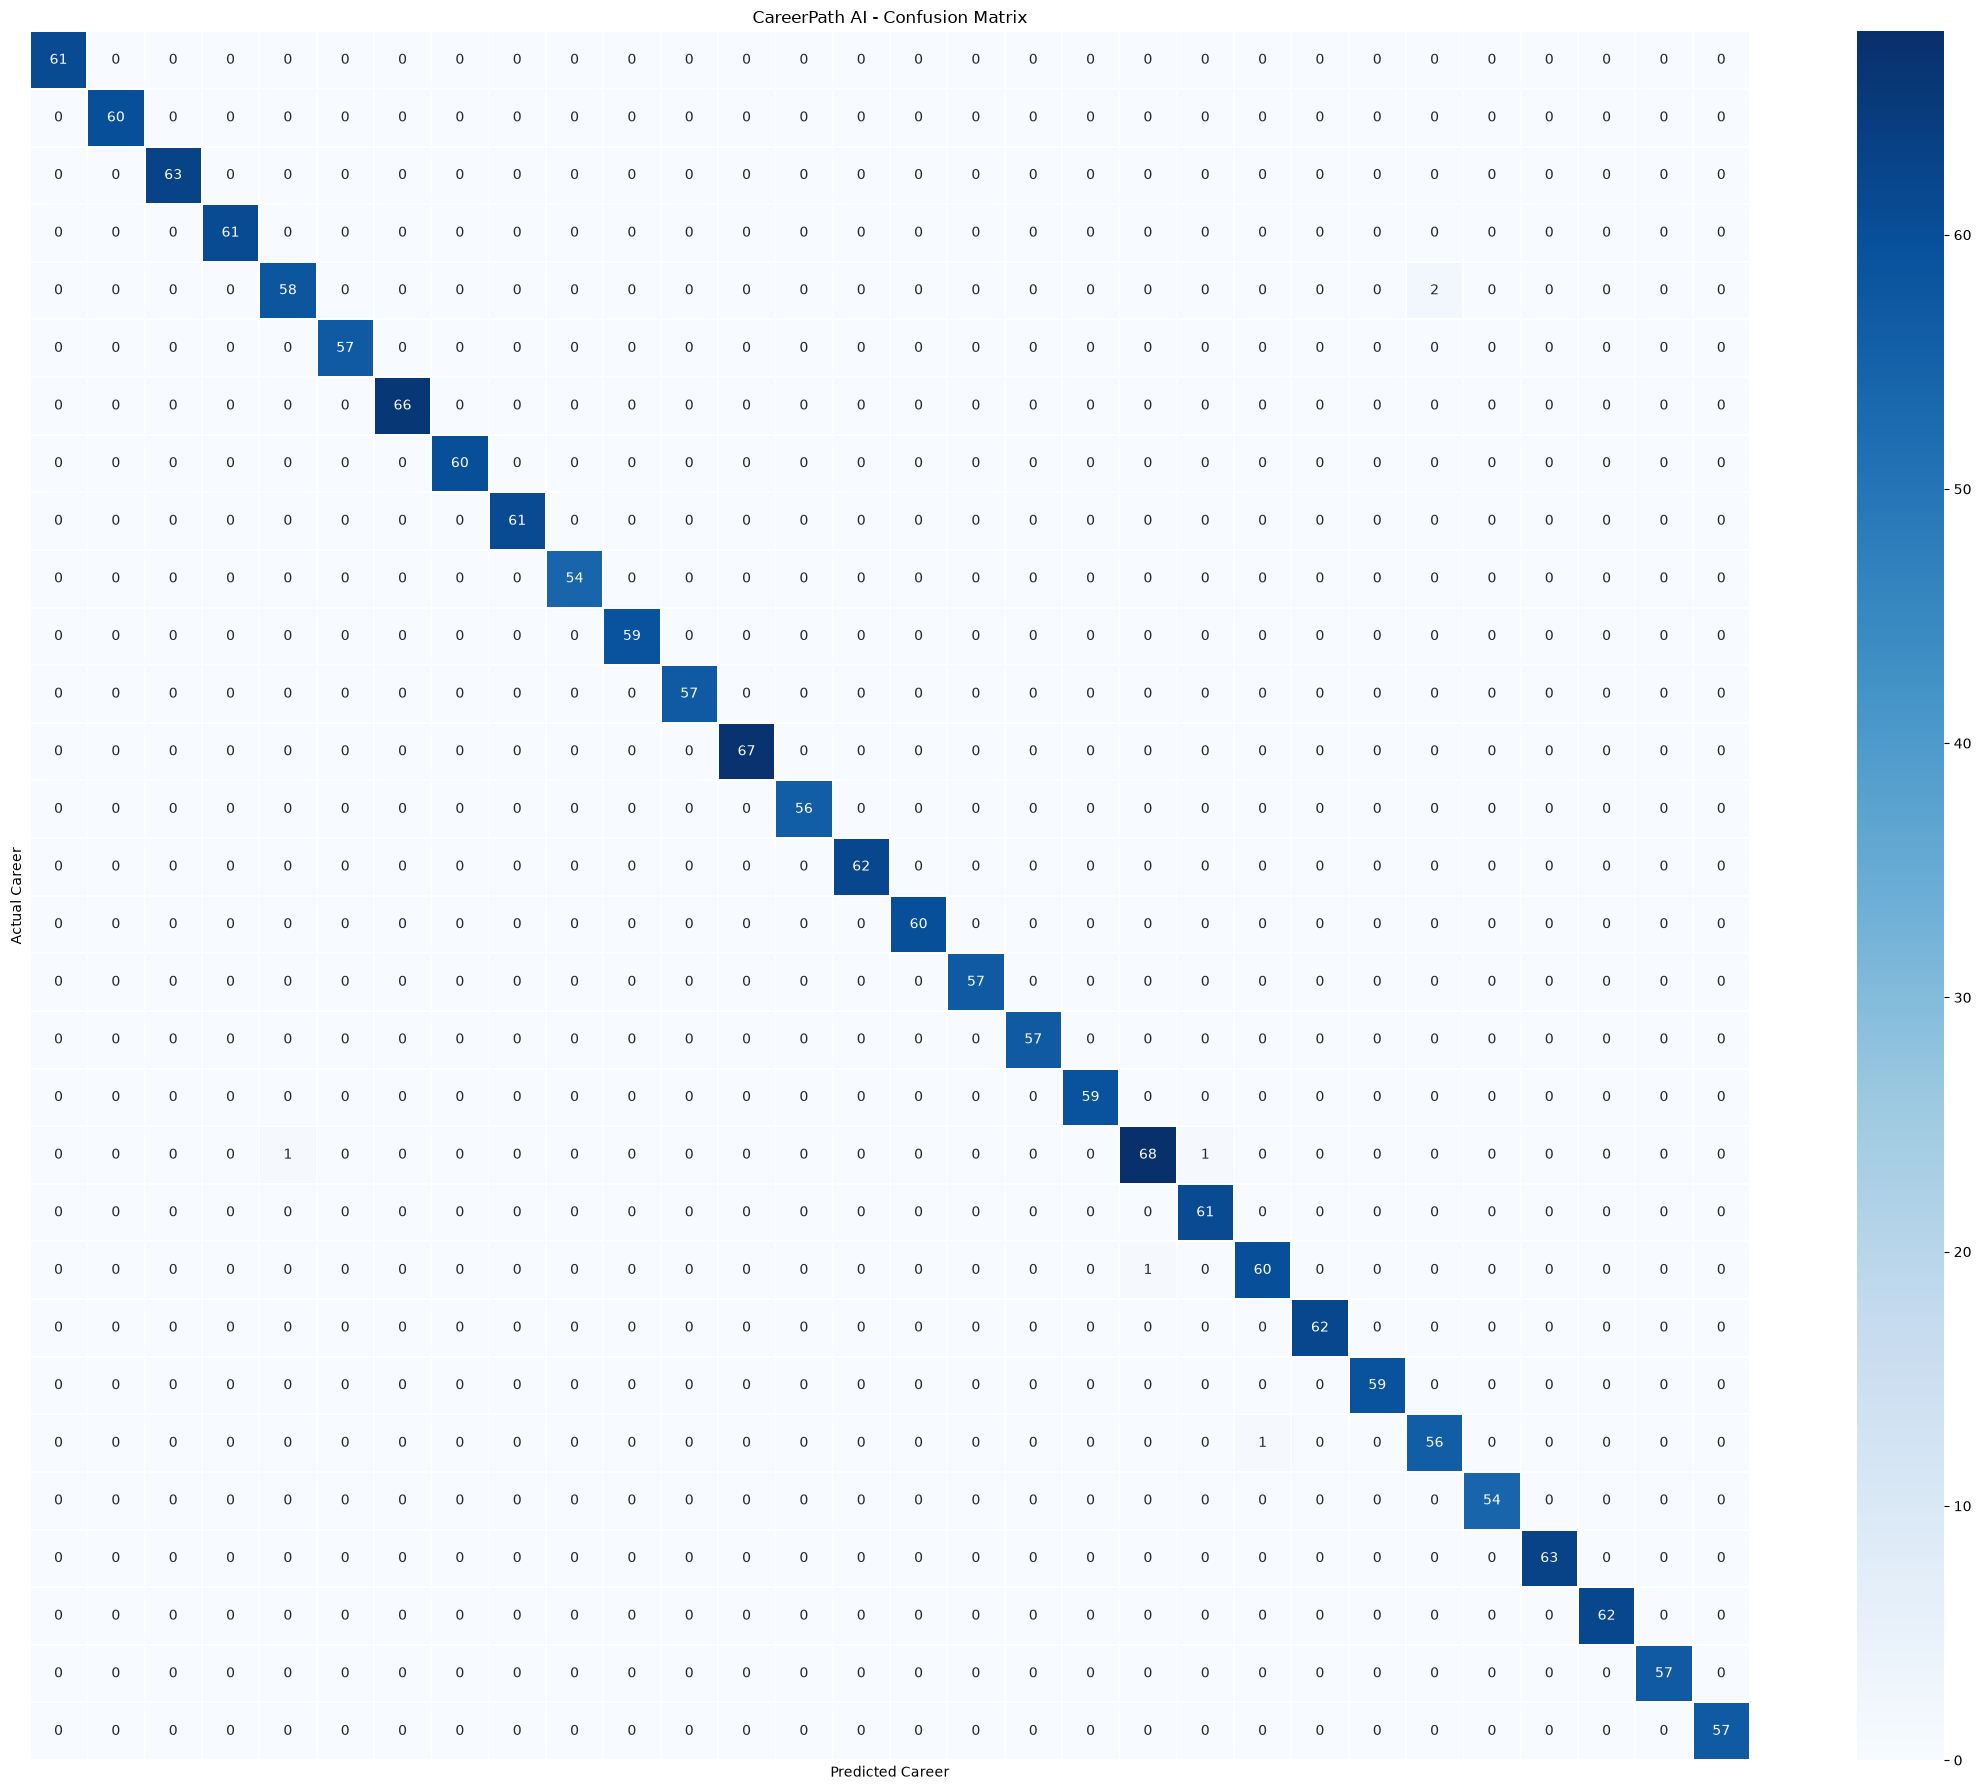

In [13]:
plt.figure(figsize=(22, 18))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=False,
    yticklabels=False,
    linewidths=0.3
)

plt.title("CareerPath AI - Confusion Matrix")
plt.xlabel("Predicted Career")
plt.ylabel("Actual Career")

plt.tight_layout()
plt.show()

In [14]:
print("Actual test records:", len(y_test))
print("Predicted records:", len(y_pred))

print("\nCorrect predictions:",
      (y_test.to_numpy() == y_pred).sum())

print("Incorrect predictions:",
      (y_test.to_numpy() != y_pred).sum())

print("\nConfusion matrix total:", cm.sum())
print("Confusion matrix diagonal total:", np.trace(cm))

print("\nConfusion matrix minimum:", cm.min())
print("Confusion matrix maximum:", cm.max())

print("\nFirst 10 actual classes:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted classes:")
print(y_pred[:10].tolist())

Actual test records: 1800
Predicted records: 1800

Correct predictions: 1794
Incorrect predictions: 6

Confusion matrix total: 1800
Confusion matrix diagonal total: 1794

Confusion matrix minimum: 0
Confusion matrix maximum: 68

First 10 actual classes:
['BiPC / relevant vocational or agriculture pathway', 'M.Tech in Engineering Specialization', 'B.Ed / M.Ed / postgraduate education specialization (subject to eligibility)', 'B.Des / BFA / BA in Media and Communication (subject to eligibility)', 'B.Com (Accounting and Finance) / BBA Finance', 'BiPC / relevant vocational or agriculture pathway', 'BiPC → Intermediate (BiPC) → B.Sc Life Sciences / Biotechnology', 'CEC / MEC → Intermediate → B.Com / Finance pathway', 'B.Ed / M.Ed / postgraduate education specialization (subject to eligibility)', 'B.Tech Computer Science and Engineering']

First 10 predicted classes:
['BiPC / relevant vocational or agriculture pathway', 'M.Tech in Engineering Specialization', 'MA in a relevant humanities or 

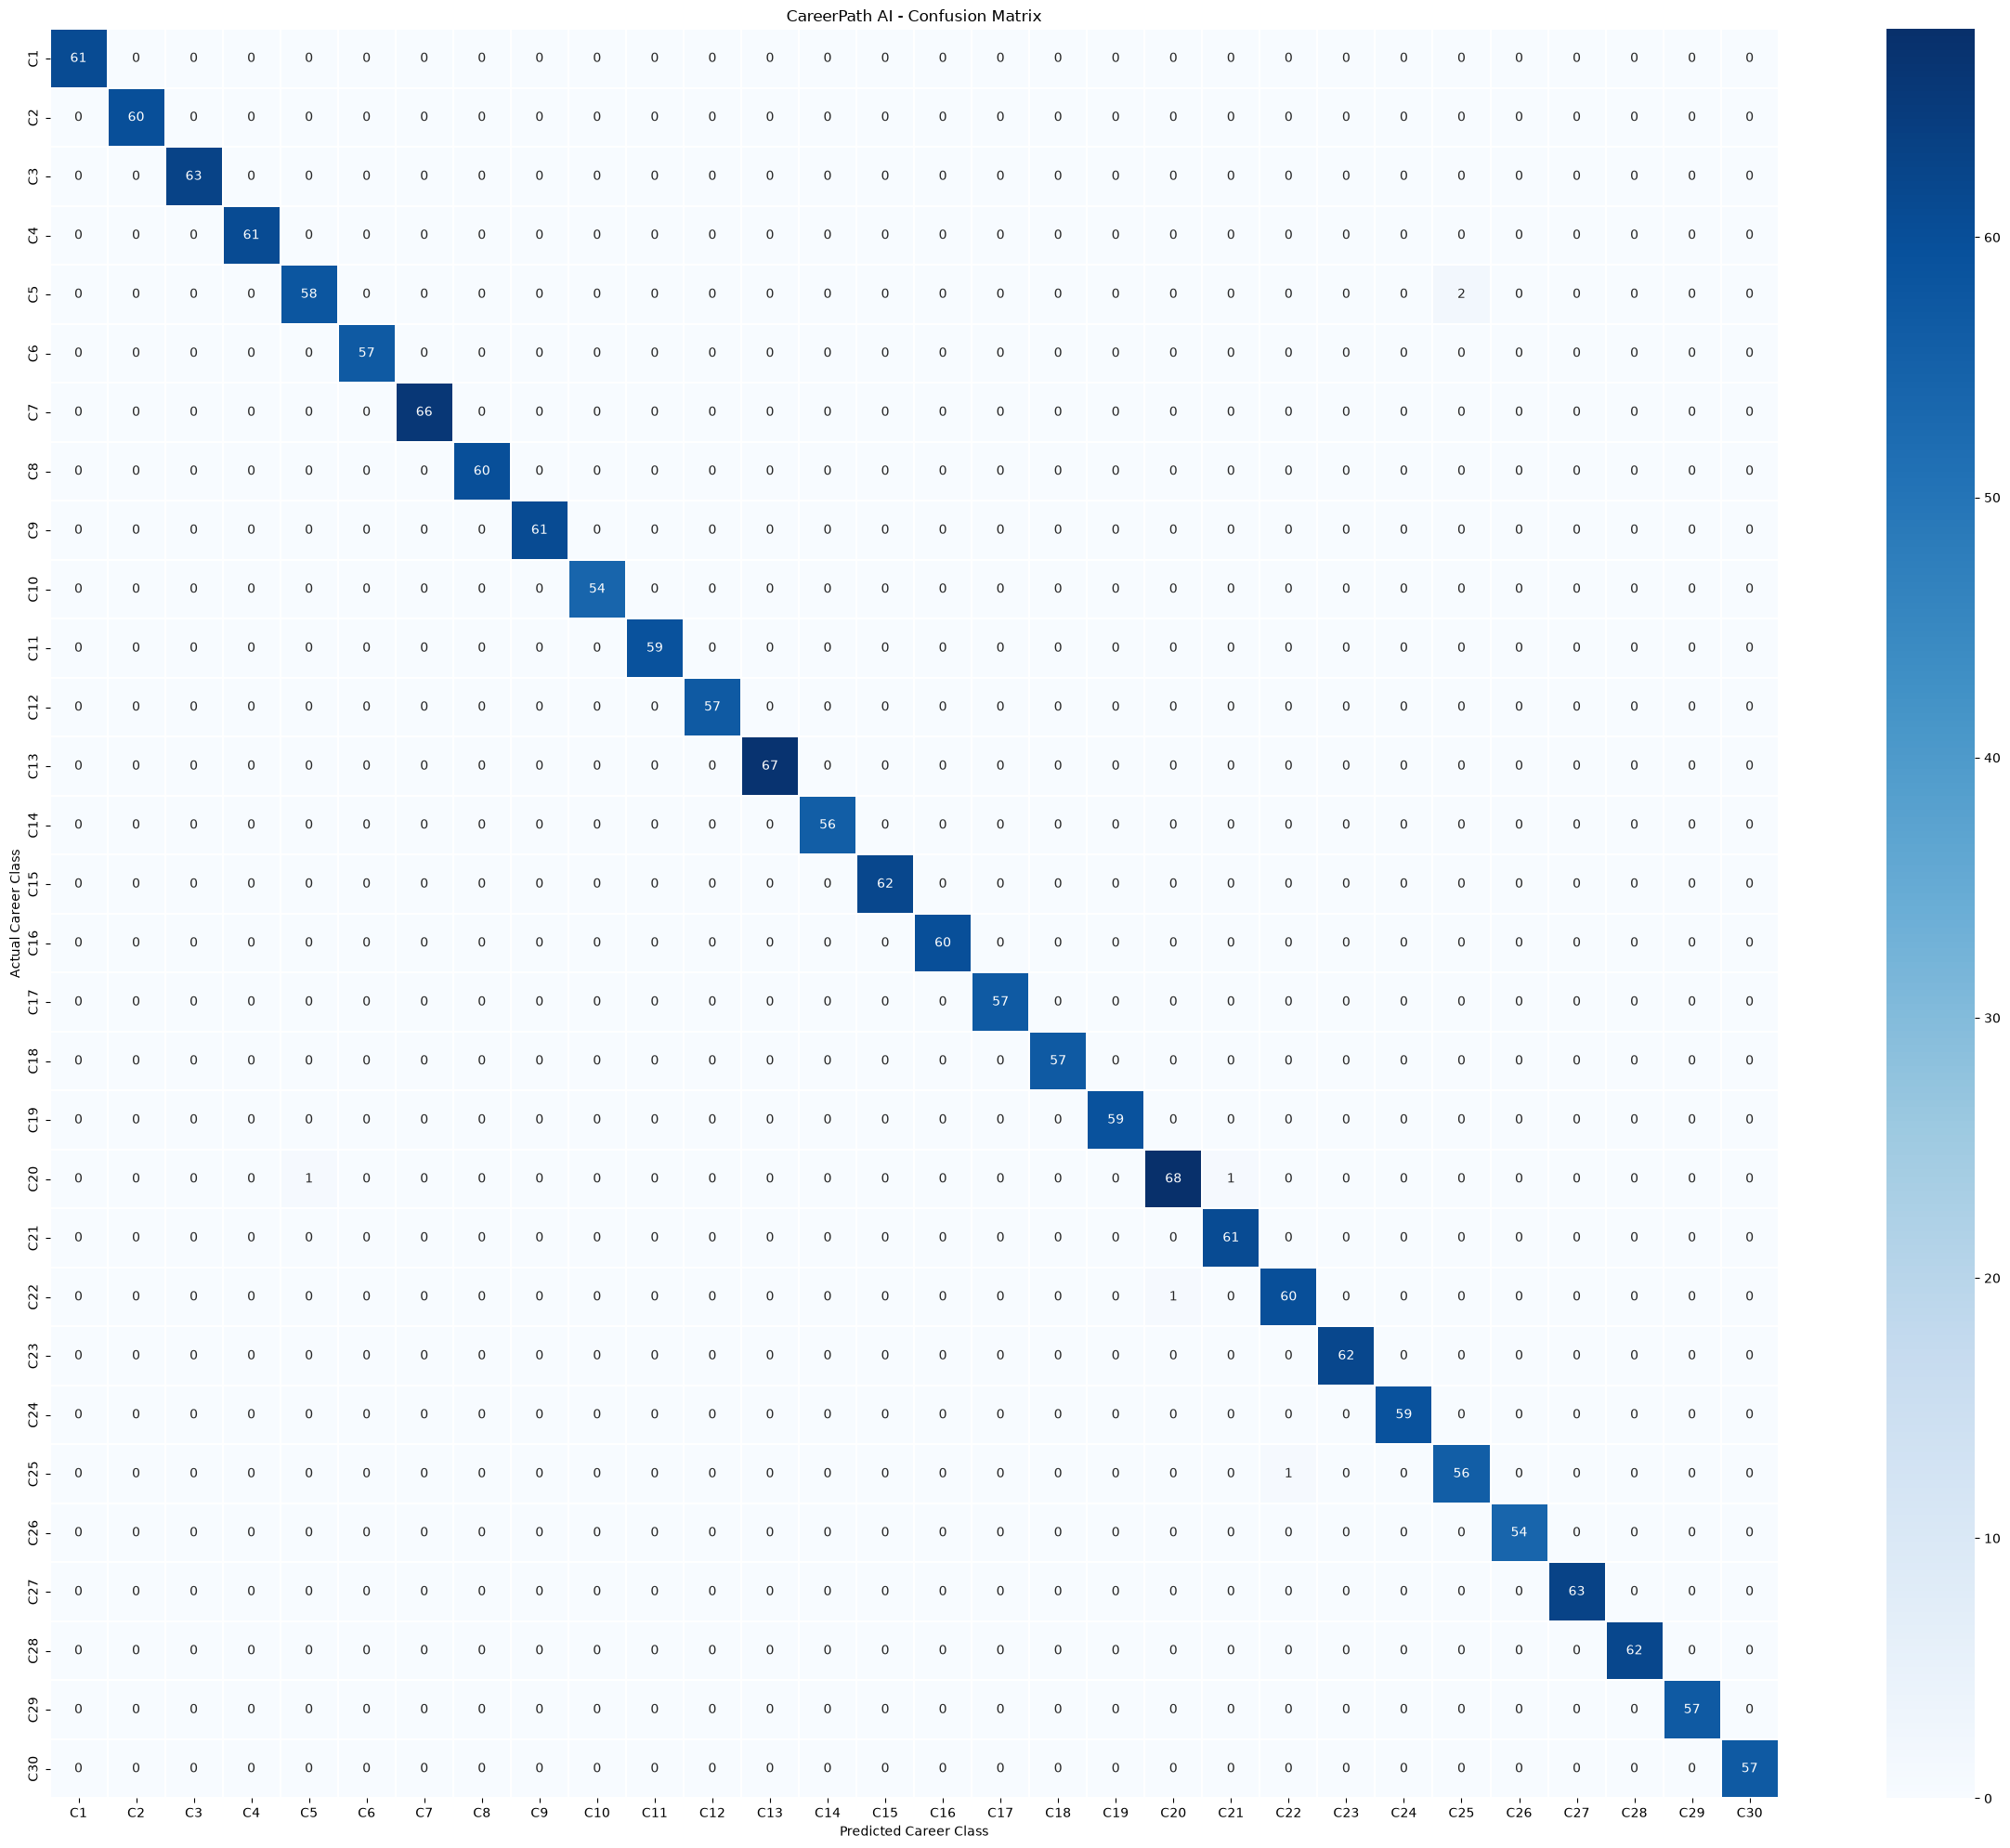

In [15]:
plt.figure(figsize=(24, 20))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        f"C{i+1}" for i in range(30)
    ],
    yticklabels=[
        f"C{i+1}" for i in range(30)
    ],
    linewidths=0.3
)

plt.title("CareerPath AI - Confusion Matrix")
plt.xlabel("Predicted Career Class")
plt.ylabel("Actual Career Class")

plt.tight_layout()
plt.show()

In [16]:
# Create a comparison DataFrame
prediction_results = pd.DataFrame({
    "Actual Career": y_test.values,
    "Predicted Career": y_pred
})

# Filter incorrect predictions
incorrect_predictions = prediction_results[
    prediction_results["Actual Career"] !=
    prediction_results["Predicted Career"]
]

print("Total incorrect predictions:", len(incorrect_predictions))

print("\nIncorrect prediction details:")
display(incorrect_predictions.reset_index(drop=True))

Total incorrect predictions: 6

Incorrect prediction details:


,Actual Career,Predicted Career
0,B.Ed / M.Ed / postgraduate education specializ...,MA in a relevant humanities or social-science ...
1,M.Sc Biotechnology / Microbiology / Life Sciences,M.Sc / postgraduate specialization in a releva...
2,B.Ed / M.Ed / postgraduate education specializ...,MA in a relevant humanities or social-science ...
3,M.Sc / postgraduate specialization in a releva...,M.Sc Agriculture / Horticulture / Food Science...
4,M.Sc / postgraduate specialization in a releva...,B.Ed / M.Ed / postgraduate education specializ...
5,MA in a relevant humanities or social-science ...,M.Sc Biotechnology / Microbiology / Life Sciences


In [17]:
# Count incorrect predictions by actual career
error_summary = (
    incorrect_predictions
    .groupby("Actual Career")
    .size()
    .reset_index(name="Error Count")
    .sort_values("Error Count", ascending=False)
)

print("ERROR DISTRIBUTION BY ACTUAL CAREER")
display(error_summary)

print("\nMost frequently confused predicted careers:")
display(
    incorrect_predictions["Predicted Career"]
    .value_counts()
    .reset_index()
)

ERROR DISTRIBUTION BY ACTUAL CAREER


,Actual Career,Error Count
0,B.Ed / M.Ed / postgraduate education specializ...,2
1,M.Sc / postgraduate specialization in a releva...,2
2,M.Sc Biotechnology / Microbiology / Life Sciences,1
3,MA in a relevant humanities or social-science ...,1



Most frequently confused predicted careers:


,Predicted Career,count
0,MA in a relevant humanities or social-science ...,2
1,M.Sc / postgraduate specialization in a releva...,1
2,M.Sc Agriculture / Horticulture / Food Science...,1
3,B.Ed / M.Ed / postgraduate education specializ...,1
4,M.Sc Biotechnology / Microbiology / Life Sciences,1


In [18]:
# Create output directories
MODEL_DIR = Path("../models")
REPORT_DIR = Path("../reports/careerpath")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model
joblib.dump(
    career_model,
    MODEL_DIR / "careerpath_logistic_regression.ipynb.joblib"
)

# Save evaluation metrics
metrics_df = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Balanced Accuracy": balanced_accuracy,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1
}])

metrics_df.to_csv(
    REPORT_DIR / "model_metrics.csv",
    index=False
)

# Save classification report
report_dict = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    REPORT_DIR / "classification_report.csv"
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=career_model.classes_,
    columns=career_model.classes_
).to_csv(REPORT_DIR / "confusion_matrix.csv")

# Save prediction results
prediction_results.to_csv(
    REPORT_DIR / "prediction_results.csv",
    index=False
)

print("MODEL AND REPORTS SAVED SUCCESSFULLY!")

print("\nSaved model:")
print(MODEL_DIR / "careerpath_logistic_regression.ipynb.joblib")

print("\nSaved reports:")
for file in REPORT_DIR.iterdir():
    print(file.name)

MODEL AND REPORTS SAVED SUCCESSFULLY!

Saved model:
..\models\careerpath_logistic_regression.ipynb.joblib

Saved reports:
classification_report.csv
confusion_matrix.csv
consolidated_evaluation.csv
cross_validation_results.csv
evaluation_summary.json
feature_ablation_results.csv
feature_combination_results.csv
feature_novelty_results.csv
individual_feature_results.csv
metrics.json
model_metrics.csv
prediction_results.csv
sanity_check_results.csv
targeted_feature_results.csv
unseen_profile_predictions.csv


In [19]:
# Load saved model
saved_model = joblib.load(
    MODEL_DIR / "careerpath_logistic_regression.ipynb.joblib"
)

# Test loaded model
sample_predictions = saved_model.predict(X_test.iloc[:5])

print("Saved model loaded successfully!")

print("\nSample predictions:")
for i, prediction in enumerate(sample_predictions, start=1):
    print(f"{i}. {prediction}")

print("\nModel verification completed!")

Saved model loaded successfully!

Sample predictions:
1. BiPC / relevant vocational or agriculture pathway
2. M.Tech in Engineering Specialization
3. MA in a relevant humanities or social-science specialization
4. B.Des / BFA / BA in Media and Communication (subject to eligibility)
5. B.Com (Accounting and Finance) / BBA Finance

Model verification completed!


# CareerPath AI – Model Training and Evaluation Summary

## 1. Dataset Overview
- Total records: 9,000
- Input features: 8
- Target variable: Recommended Career
- Career categories: 30
- Training records: 7,200
- Testing records: 1,800

## 2. Machine Learning Algorithm
**Logistic Regression**

Parameters:
- max_iter = 2000
- C = 1.0
- random_state = 42

## 3. Preprocessing Techniques
- One-Hot Encoding for categorical features
- StandardScaler for numerical features
- TF-IDF Vectorization for technical skills
- TF-IDF Vectorization for soft skills
- TF-IDF Vectorization for skills gained

## 4. Model Performance

| Metric | Score |
|---|---:|
| Accuracy | 99.67% |
| Balanced Accuracy | 99.68% |
| Macro F1 | 99.68% |
| Weighted F1 | 99.67% |

## 5. Baseline Comparison
The Logistic Regression model substantially outperformed the most-frequent DummyClassifier baseline.

## 6. Error Analysis
- Total test predictions: 1,800
- Correct predictions: 1,794
- Incorrect predictions: 6
- Main confusion areas involved related education and postgraduate career pathways.

## 7. Model Saving and Verification
Saved model:
`models/careerpath_logistic_regression.ipynb.joblib`

Evaluation reports saved in:
`reports/careerpath/`

The saved model was successfully loaded using Joblib and tested with sample predictions.

## 8. Dataset Limitations
- The dataset appears to contain synthetic or rule-generated career patterns.
- Very high test accuracy should not be interpreted as real-world career suitability.
- Career recommendations require validation using independent, real-world student data.
- Academic eligibility, personal interests, financial constraints and individual preferences are not fully represented by this classification model.

## Conclusion
CareerPath AI successfully trained a multiclass Logistic Regression model using structured student profiles and skill-based text features. The model and evaluation reports were saved successfully and are ready for further testing and integration.

**Notebook Status: Completed**
